# Student Mental Health Score Prediction Using Linear Regression
Name : Umer Farooq
reg no:B24F0418Ai076

## Block 1: Import libraries

In [78]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42   # keeps your split and results reproducible
print("Libraries loaded.")

Libraries loaded.


## Block 2: Load the dataset and take a first look

In [79]:
df = pd.read_csv("AI_SocialMedia_Student_Dataset.csv")
print("Rows (instances):", df.shape[0])
print("Columns (attributes):", df.shape[1])
df.head()

Rows (instances): 16000
Columns (attributes): 10


,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_ID                 16000 non-null  object 
 1   Age                        16000 non-null  int64  
 2   Gender                     16000 non-null  object 
 3   Education_Level            16000 non-null  object 
 4   Daily_Social_Media_Hours   16000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours  16000 non-null  float64
 6   Sleep_Hours                16000 non-null  float64
 7   Physical_Activity_Hours    16000 non-null  float64
 8   Mental_Health_Score        16000 non-null  float64
 9   Physical_Health_Score      16000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 1.2+ MB


## Block 3: Data understanding (type, range, mode, skewness, kurtosis)

In [81]:
num_df = df.select_dtypes(include="number")

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "mode": df.mode().iloc[0],
})
summary["min"] = num_df.min()
summary["max"] = num_df.max()
summary["mean"] = num_df.mean().round(2)
summary["std"] = num_df.std().round(2)
summary["skewness"] = num_df.skew().round(3)
summary["kurtosis"] = num_df.kurt().round(3)   # pandas gives EXCESS kurtosis (normal = 0)
summary

,dtype,unique_values,mode,min,max,mean,std,skewness,kurtosis
Student_ID,object,16000,STU_00001,NaN,NaN,NaN,NaN,NaN,NaN
Age,int64,13,25.0,13.00,25.00,19.04,3.77,-0.011,-1.218
Gender,object,3,Male,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,object,3,High School,NaN,NaN,NaN,NaN,NaN,NaN
Daily_Social_Media_Hours,float64,1106,0.0,0.00,14.00,4.54,2.40,0.157,-0.348
Daily_AI_Tool_Usage_Hours,float64,762,0.0,0.00,9.50,2.59,1.68,0.338,-0.369
Sleep_Hours,float64,752,6.63,2.00,11.15,6.55,1.27,0.015,-0.005
Physical_Activity_Hours,float64,462,0.0,0.00,5.00,1.25,1.04,0.619,-0.273
Mental_Health_Score,float64,3743,72.85,32.56,91.76,72.49,9.24,-0.683,0.244
Physical_Health_Score,float64,3433,99.9,48.03,99.98,88.02,9.69,-0.749,-0.038


In [82]:
df.describe().round(2)

,Age,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
count,16000.00,16000.00,16000.00,16000.00,16000.00,16000.00,16000.00
mean,19.04,4.54,2.59,6.55,1.25,72.49,88.02
std,3.77,2.40,1.68,1.27,1.04,9.24,9.69
min,13.00,0.00,0.00,2.00,0.00,32.56,48.03
25%,16.00,2.84,1.31,5.68,0.31,66.76,81.52
50%,19.00,4.50,2.52,6.54,1.13,73.75,89.46
75%,22.00,6.18,3.75,7.41,1.96,79.55,97.17
max,25.00,14.00,9.50,11.15,5.00,91.76,99.98


In [83]:
print(df["Gender"].value_counts(), "\n")
print(df["Education_Level"].value_counts())

Gender
Male          7744
Female        7628
Non-binary     628
Name: count, dtype: int64 

Education_Level
High School    6083
University     5027
College        4890
Name: count, dtype: int64


## Block 4: Data cleaning
Checks: missing values, duplicates, wrong data types, irrelevant columns, impossible values.

In [84]:
# 4.1 Missing values
print("Missing values per column:")
print(df.isnull().sum())

# 4.2 Duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Student_IDs:", df["Student_ID"].duplicated().sum())

Missing values per column:
Student_ID                   0
Age                          0
Gender                       0
Education_Level              0
Daily_Social_Media_Hours     0
Daily_AI_Tool_Usage_Hours    0
Sleep_Hours                  0
Physical_Activity_Hours      0
Mental_Health_Score          0
Physical_Health_Score        0
dtype: int64

Duplicate rows: 0
Duplicate Student_IDs: 0


In [85]:
# 4.3 Remove duplicates (none expected, but the code stays for completeness)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows removed:", before - len(df))

# 4.4 Missing values (nothing is missing in this file, so this is a safety net)
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())
for col in ["Gender", "Education_Level"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# 4.5 Fix data types / tidy text in categorical columns
for col in ["Gender", "Education_Level"]:
    df[col] = df[col].astype(str).str.strip().str.title().astype("category")

# 4.6 Drop irrelevant variable: Student_ID is just a label, it has no predictive meaning
df = df.drop(columns=["Student_ID"])

print(df.dtypes)

Rows removed: 0
Age                             int64
Gender                       category
Education_Level              category
Daily_Social_Media_Hours      float64
Daily_AI_Tool_Usage_Hours     float64
Sleep_Hours                   float64
Physical_Activity_Hours       float64
Mental_Health_Score           float64
Physical_Health_Score         float64
dtype: object


In [86]:
# 4.7 Impossible-value checks (logical validation)
total_hours = (df["Daily_Social_Media_Hours"] + df["Daily_AI_Tool_Usage_Hours"]
               + df["Sleep_Hours"] + df["Physical_Activity_Hours"])

checks = {
    "Any hours column > 24":               (df.filter(like="Hours") > 24).any(axis=1).sum(),
    "Any hours column < 0":                (df.filter(like="Hours") < 0).any(axis=1).sum(),
    "Scores outside 0-100":                ((df[["Mental_Health_Score", "Physical_Health_Score"]] < 0) |
                                            (df[["Mental_Health_Score", "Physical_Health_Score"]] > 100)).any(axis=1).sum(),
    "Total tracked hours > 24":            (total_hours > 24).sum(),
}
for name, count in checks.items():
    print(f"{name}: {count}")

Any hours column > 24: 0
Any hours column < 0: 0
Scores outside 0-100: 0
Total tracked hours > 24: 0


## Block 5: Exploratory Data Analysis (EDA)

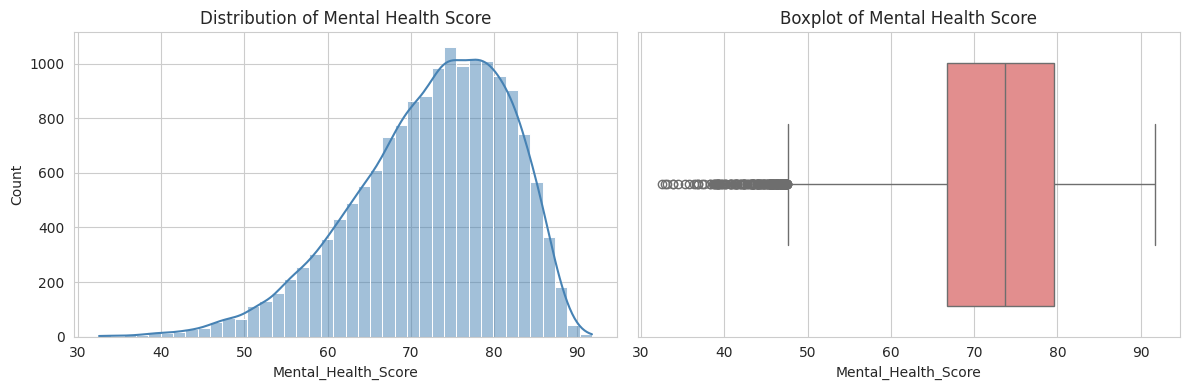

In [87]:
# 5.1 Target variable
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Mental_Health_Score"], kde=True, bins=40, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of Mental Health Score")
sns.boxplot(x=df["Mental_Health_Score"], ax=ax[1], color="lightcoral")
ax[1].set_title("Boxplot of Mental Health Score")
plt.tight_layout()
plt.show()

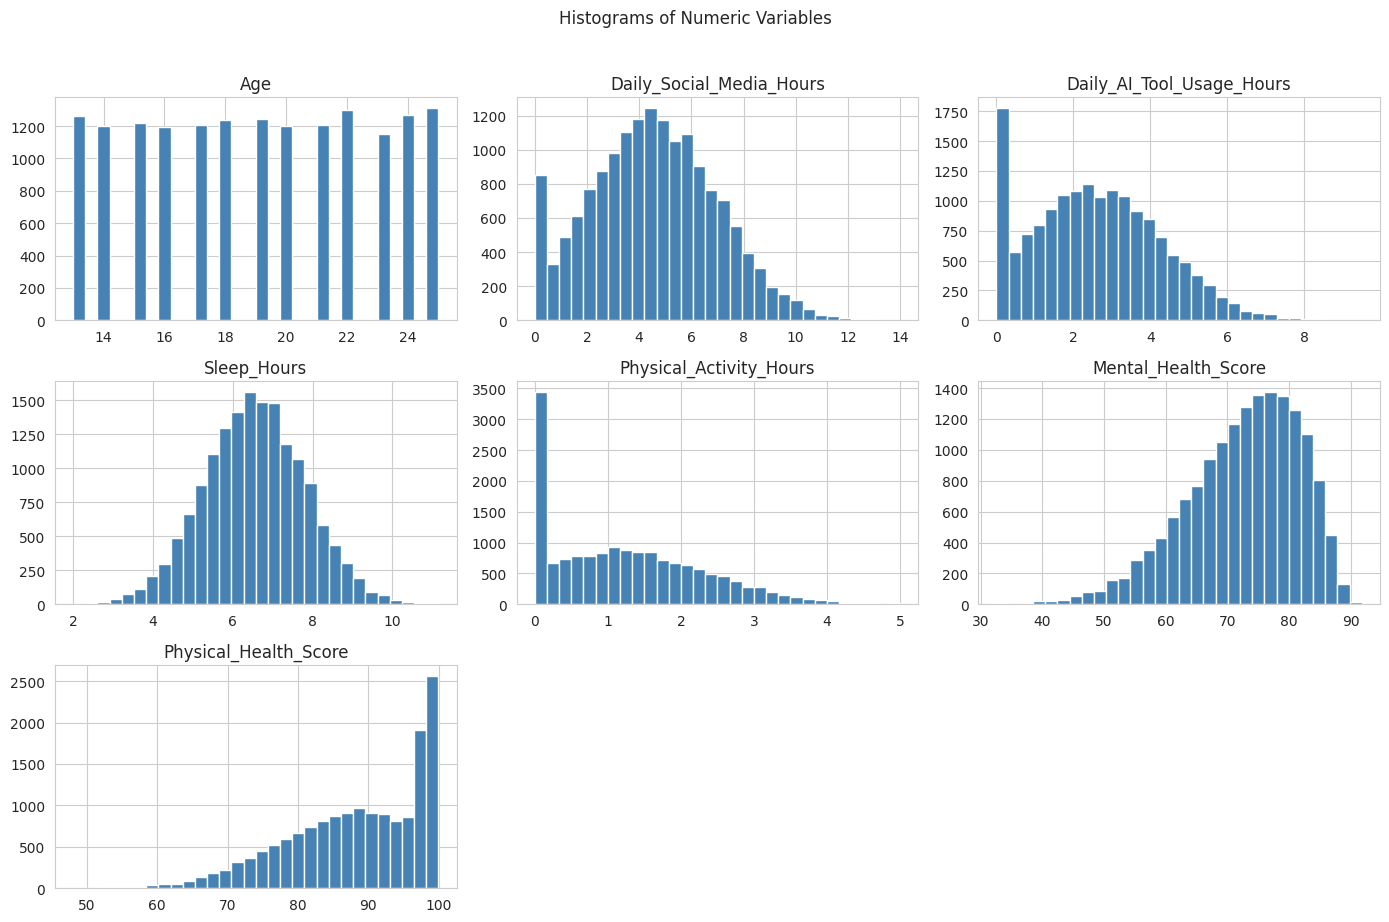

In [88]:
# 5.2 Histograms of all numeric columns
num_cols_eda = df.select_dtypes(include="number").columns
df[num_cols_eda].hist(bins=30, figsize=(14, 9), color="steelblue", edgecolor="white")
plt.suptitle("Histograms of Numeric Variables", y=1.02)
plt.tight_layout()
plt.show()

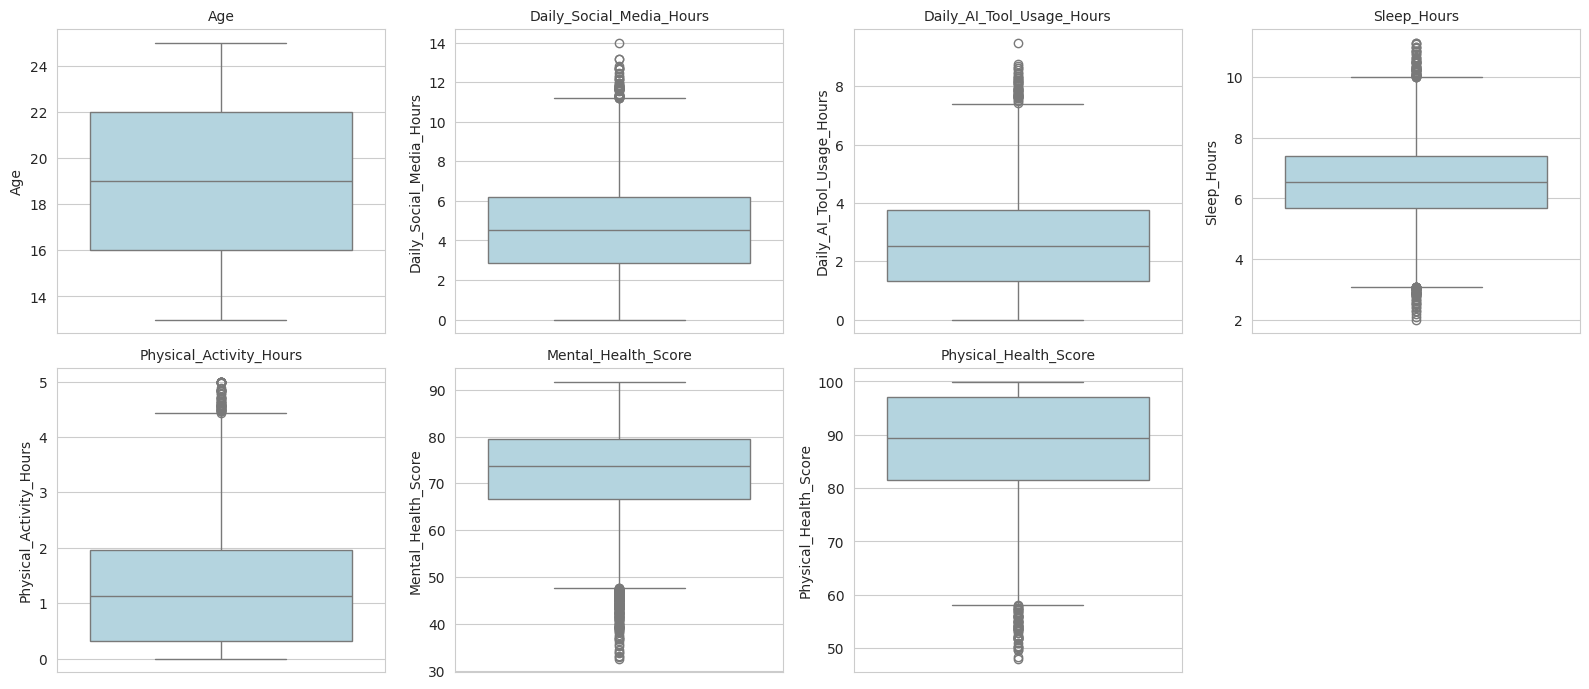

In [89]:
# 5.3 Boxplots (visual outlier check)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols_eda):
    sns.boxplot(y=df[col], ax=ax, color="lightblue")
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

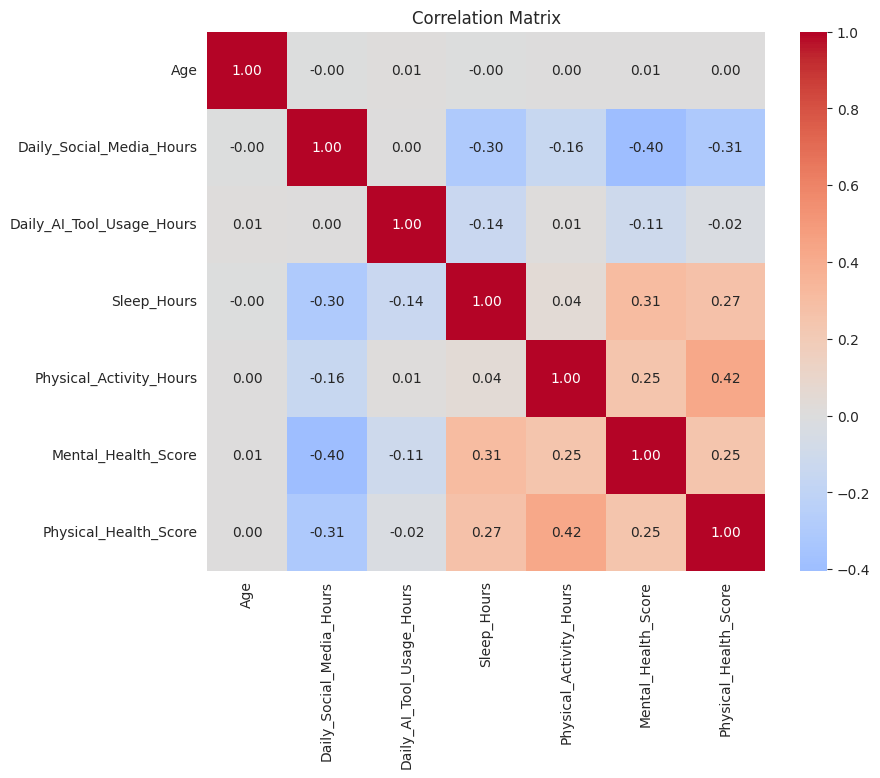

In [90]:
# 5.4 Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

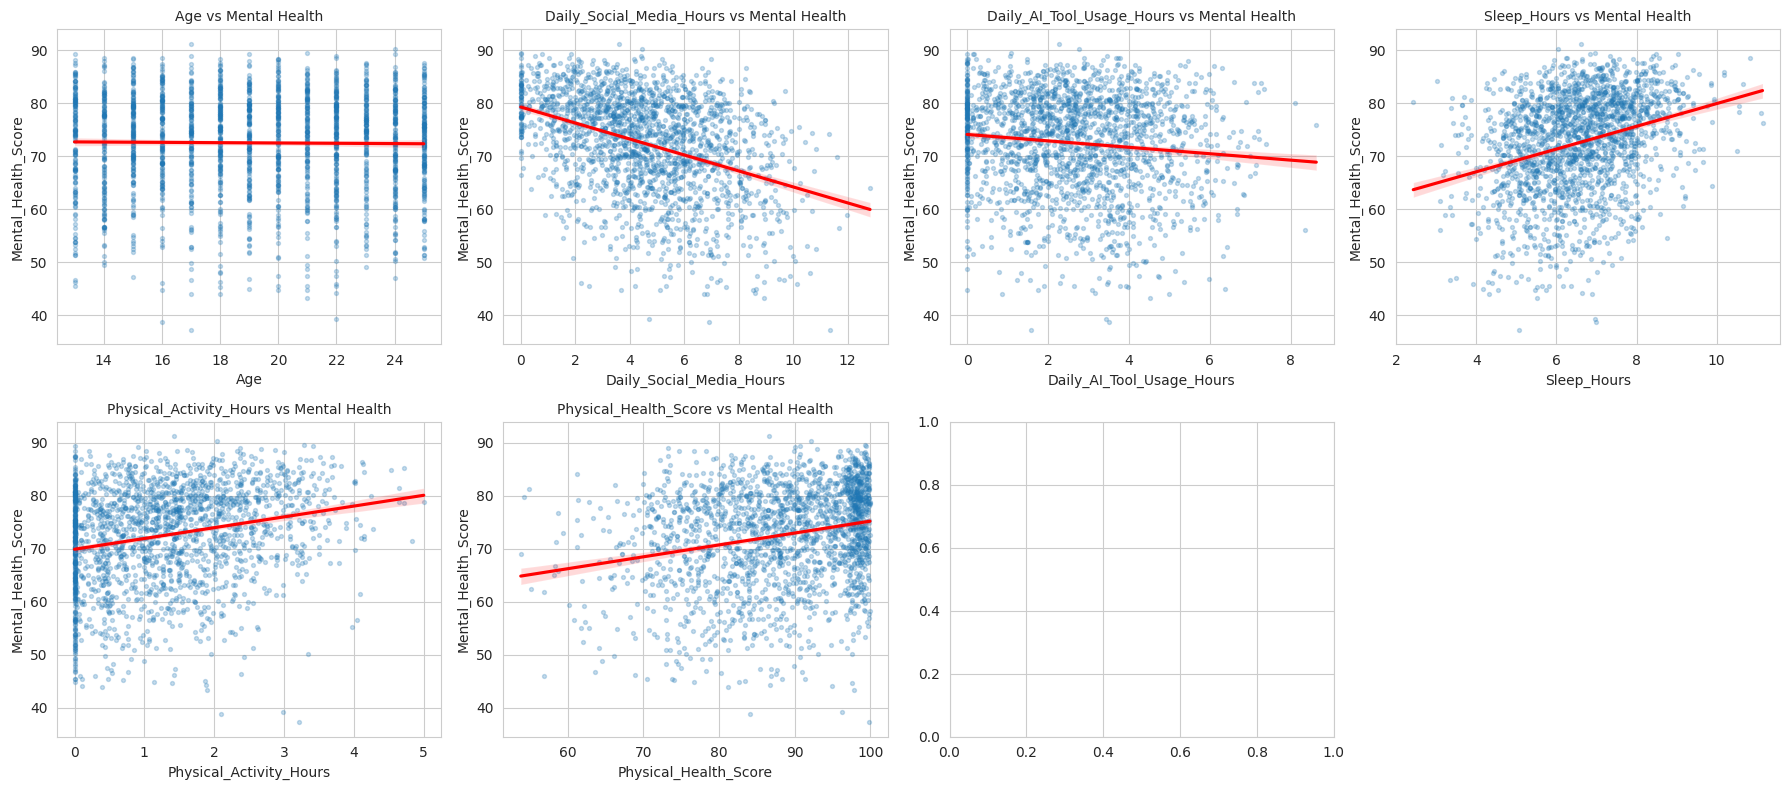

In [91]:
# 5.5 Each numeric feature vs the target
features_to_plot = [c for c in num_cols_eda if c != "Mental_Health_Score"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
sample = df.sample(2000, random_state=RANDOM_STATE)   # sample so the plots stay readable
for ax, col in zip(axes.ravel(), features_to_plot):
    sns.regplot(data=sample, x=col, y="Mental_Health_Score", ax=ax,
                scatter_kws={"alpha": 0.25, "s": 8}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs Mental Health", fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

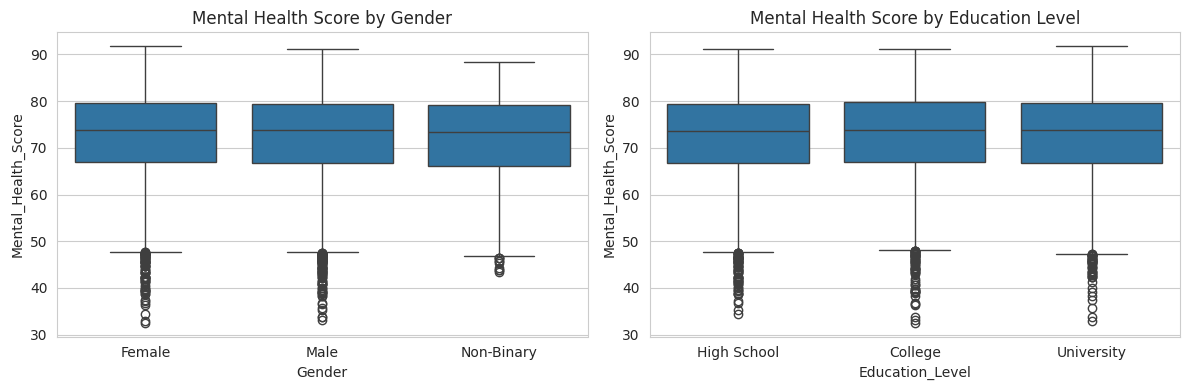

Gender
Female        72.54
Male          72.48
Non-Binary    72.12
Name: Mental_Health_Score, dtype: float64 

Education_Level
College        72.68
High School    72.34
University     72.49
Name: Mental_Health_Score, dtype: float64


In [92]:
# 5.6 Categorical variables vs the target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Gender", y="Mental_Health_Score", ax=ax[0])
ax[0].set_title("Mental Health Score by Gender")
sns.boxplot(data=df, x="Education_Level", y="Mental_Health_Score", ax=ax[1],
            order=["High School", "College", "University"])
ax[1].set_title("Mental Health Score by Education Level")
plt.tight_layout()
plt.show()

print(df.groupby("Gender", observed=True)["Mental_Health_Score"].mean().round(2), "\n")
print(df.groupby("Education_Level", observed=True)["Mental_Health_Score"].mean().round(2))

## Block 6: Outlier detection (IQR method)
We only *detect* here. Capping is done later inside the pipeline so that the limits come from the training data only.

In [93]:
rows = []
for col in num_cols_eda:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low, 2), round(high, 2), n_out, round(100 * n_out / len(df), 2)])

outlier_table = pd.DataFrame(rows, columns=["Column", "Lower limit", "Upper limit", "Outliers", "% of rows"])
outlier_table

,Column,Lower limit,Upper limit,Outliers,% of rows
0,Age,7.00,31.00,0,0.00
1,Daily_Social_Media_Hours,-2.17,11.19,49,0.31
2,Daily_AI_Tool_Usage_Hours,-2.35,7.41,51,0.32
3,Sleep_Hours,3.08,10.01,105,0.66
4,Physical_Activity_Hours,-2.16,4.43,55,0.34
5,Mental_Health_Score,47.58,98.73,185,1.16
6,Physical_Health_Score,58.04,120.65,63,0.39


## Block 7: Feature engineering
The raw file has only 8 usable inputs (the task asks for 10 to 15), so we create 4 extra features.
We use ratio and threshold features instead of simple sums, because sums of existing columns
would be perfectly collinear with them and make the coefficients unstable.

In [94]:
df_fe = df.copy()

# share of daily screen time that goes to AI tools (0 if there is no screen time at all)
screen_total = df_fe["Daily_Social_Media_Hours"] + df_fe["Daily_AI_Tool_Usage_Hours"]
df_fe["AI_Share_of_Screen_Time"] = np.where(screen_total > 0, df_fe["Daily_AI_Tool_Usage_Hours"] / screen_total, 0)

# simple behaviour flags (1 = yes, 0 = no)
df_fe["Heavy_Social_Media"] = (df_fe["Daily_Social_Media_Hours"] >= 6).astype(int)
df_fe["Low_Sleep"] = (df_fe["Sleep_Hours"] < 6).astype(int)
df_fe["Inactive"] = (df_fe["Physical_Activity_Hours"] < 0.5).astype(int)

print("Input variables now:", df_fe.shape[1] - 1)
print(df_fe[["Heavy_Social_Media", "Low_Sleep", "Inactive"]].mean().round(3))
df_fe.head()

Input variables now: 12
Heavy_Social_Media    0.274
Low_Sleep             0.332
Inactive              0.303
dtype: float64


,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,AI_Share_of_Screen_Time,Heavy_Social_Media,Low_Sleep,Inactive
0,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,0.185299,0,0,0
1,16,Non-Binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,0.427473,0,0,0
2,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,0.423323,0,0,1
3,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,0.327982,0,0,0
4,20,Non-Binary,College,6.52,1.64,5.23,1.14,67.74,88.04,0.200980,1,1,0


### Export Processed Dataset
This cell saves a copy of the fully cleaned and engineered dataset as a new CSV file, then initiates a download.

In [95]:
import pandas as pd
import numpy as np
import os

try:
    # Use df_fe directly if it is already defined in the namespace
    if 'df_fe' in globals():
        df_export = df_fe
    else:
        # Fallback: recreate the cleaned dataframe if raw data is found
        csv_name = "AI_SocialMedia_Student_Dataset.csv"
        if os.path.exists(csv_name):
            df_temp = pd.read_csv(csv_name)
        elif 'df' in globals():
            df_temp = df.copy()
        else:
            raise FileNotFoundError("Variables 'df' or 'df_fe' were not found in memory, and 'AI_SocialMedia_Student_Dataset.csv' is missing from the file directory. Please run the notebook from the beginning or upload the CSV file.")

        # Standardize cleaning steps on the loaded raw dataset
        df_temp = df_temp.drop_duplicates().reset_index(drop=True)
        for col in df_temp.select_dtypes(include='number').columns:
            df_temp[col] = df_temp[col].fillna(df_temp[col].median())
        for col in ["Gender", "Education_Level"]:
            df_temp[col] = df_temp[col].fillna(df_temp[col].mode()[0])
            df_temp[col] = df_temp[col].astype(str).str.strip().str.title()
        df_temp = df_temp.drop(columns=["Student_ID"], errors="ignore")

        # Feature Engineering
        screen_total = df_temp["Daily_Social_Media_Hours"] + df_temp["Daily_AI_Tool_Usage_Hours"]
        df_temp["AI_Share_of_Screen_Time"] = np.where(screen_total > 0, df_temp["Daily_AI_Tool_Usage_Hours"] / screen_total, 0)
        df_temp["Heavy_Social_Media"] = (df_temp["Daily_Social_Media_Hours"] >= 6).astype(int)
        df_temp["Low_Sleep"] = (df_temp["Sleep_Hours"] < 6).astype(int)
        df_temp["Inactive"] = (df_temp["Physical_Activity_Hours"] < 0.5).astype(int)
        df_export = df_temp

    # Save copy of file locally to the workspace
    output_filename = "cleaned_student_dataset.csv"
    df_export.to_csv(output_filename, index=False)
    print(f"Successfully saved processed dataset to {output_filename}")
except Exception as e:
    print(f"An error occurred: {e}")

Successfully saved processed dataset to cleaned_student_dataset.csv


## Block 8: Define X and y, then split 80% train / 20% test

In [96]:
target = "Mental_Health_Score"
X = df_fe.drop(columns=[target])
y = df_fe[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, "->", round(100 * len(X_train) / len(X)), "%")
print("Testing set :", X_test.shape, "->", round(100 * len(X_test) / len(X)), "%")

Training set: (12800, 12) -> 80 %
Testing set : (3200, 12) -> 20 %


## Block 9: Preprocessing pipeline (outlier capping + one-hot encoding + scaling)
Everything is fitted on the training data only, so no information leaks from the test set.

In [97]:
cat_features = ["Gender", "Education_Level"]
flag_features = ["Heavy_Social_Media", "Low_Sleep", "Inactive"]          # 0/1 columns: no capping needed
num_features = [c for c in X.columns if c not in cat_features + flag_features]   # continuous columns


class IQRCapper(BaseEstimator, TransformerMixin):
    """Caps values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]. Limits are learned from training data only."""
    def __init__(self, columns, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        q1 = X[self.columns].quantile(0.25)
        q3 = X[self.columns].quantile(0.75)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X = X.copy()
        X[self.columns] = X[self.columns].clip(self.lower_, self.upper_, axis=1)
        return X


encode_and_scale = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("flag", "passthrough", flag_features),
    ("cat", OneHotEncoder(drop="first"), cat_features),   # drop="first" avoids the dummy-variable trap
])

preprocessor = Pipeline([
    ("capper", IQRCapper(columns=num_features)),
    ("encode_scale", encode_and_scale),
])

# fit on train, then apply to test
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

feature_names = [n.split("__")[1] for n in preprocessor.named_steps["encode_scale"].get_feature_names_out()]
print("Features after preprocessing:", X_train_t.shape[1])
for name in feature_names:
    print(name)

Features after preprocessing: 14
Age
Daily_Social_Media_Hours
Daily_AI_Tool_Usage_Hours
Sleep_Hours
Physical_Activity_Hours
Physical_Health_Score
AI_Share_of_Screen_Time
Heavy_Social_Media
Low_Sleep
Inactive
Gender_Male
Gender_Non-Binary
Education_Level_High School
Education_Level_University


## Block 10: Train the Linear Regression model

In [98]:
lin_pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])

start = time.time()
lin_pipe.fit(X_train, y_train)
lin_train_time = time.time() - start

print(f"Model trained in {lin_train_time:.4f} seconds")
print("Intercept:", round(lin_pipe.named_steps["model"].intercept_, 3))

Model trained in 0.0410 seconds
Intercept: 72.844


## Block 11: Model evaluation (accuracy, error rate, generalization)

In [99]:
def evaluate(model, X_tr, y_tr, X_te, y_te, name="Model"):
    results = []
    for label, Xs, ys in [("Train", X_tr, y_tr), ("Test", X_te, y_te)]:
        pred = model.predict(Xs)
        mse = mean_squared_error(ys, pred)
        results.append({
            "Model": name, "Set": label,
            "R2": r2_score(ys, pred),
            "MAE": mean_absolute_error(ys, pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAPE %": np.mean(np.abs((ys - pred) / ys)) * 100,
        })
    return pd.DataFrame(results)

lin_results = evaluate(lin_pipe, X_train, y_train, X_test, y_test, "Linear Regression")
lin_results.round(4)

,Model,Set,R2,MAE,MSE,RMSE,MAPE %
0,Linear Regression,Train,0.2476,6.3729,64.4962,8.0310,9.3907
1,Linear Regression,Test,0.2390,6.3280,64.2045,8.0128,9.2751


In [100]:
# Generalization check: gap between train and test, plus 5-fold cross-validation
r2_gap = lin_results.loc[0, "R2"] - lin_results.loc[1, "R2"]
print(f"Train R2 - Test R2 gap: {r2_gap:.4f}  (close to 0 = no overfitting)")

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(lin_pipe, X_train, y_train, cv=cv, scoring="r2")
print("5-fold CV R2 scores:", cv_r2.round(4))
print(f"Mean CV R2: {cv_r2.mean():.4f}  (+/- {cv_r2.std():.4f})")

Train R2 - Test R2 gap: 0.0086  (close to 0 = no overfitting)
5-fold CV R2 scores: [0.2564 0.2456 0.2312 0.2568 0.2387]
Mean CV R2: 0.2457  (+/- 0.0100)


## Block 12: Diagnostic plots

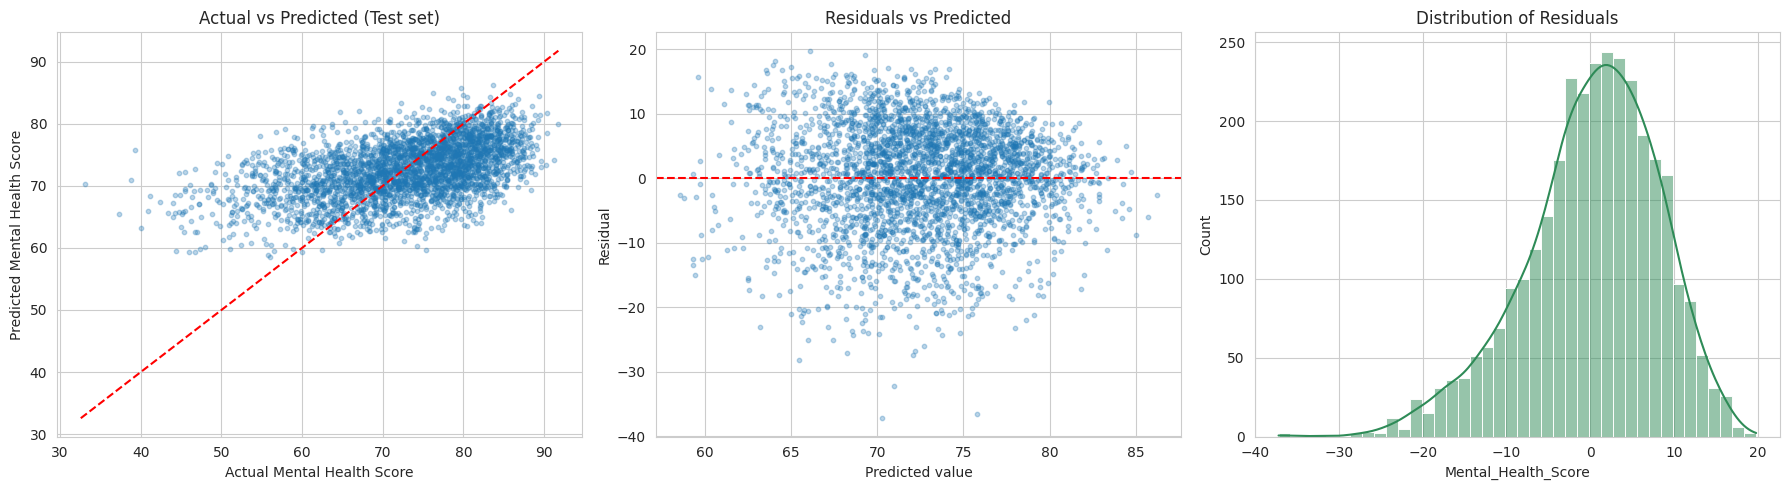

In [101]:
y_pred = lin_pipe.predict(X_test)
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(y_test, y_pred, alpha=0.3, s=10)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual Mental Health Score")
ax[0].set_ylabel("Predicted Mental Health Score")
ax[0].set_title("Actual vs Predicted (Test set)")

ax[1].scatter(y_pred, residuals, alpha=0.3, s=10)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted value")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, bins=40, ax=ax[2], color="seagreen")
ax[2].set_title("Distribution of Residuals")

plt.tight_layout()
plt.show()

## Block 13: Interpreting the model (coefficients and multicollinearity)

In [102]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lin_pipe.named_steps["model"].coef_,
})
coef_df["Abs"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs", ascending=False).drop(columns="Abs").reset_index(drop=True)
print("Numeric features are standardised, so their coefficients are comparable in size.")
coef_df.round(3)

Numeric features are standardised, so their coefficients are comparable in size.


,Feature,Coefficient
0,Daily_Social_Media_Hours,-2.948
1,Sleep_Hours,1.802
2,Physical_Activity_Hours,1.496
3,Inactive,-0.578
4,Daily_AI_Tool_Usage_Hours,-0.557
5,Education_Level_University,0.479
6,Heavy_Social_Media,-0.398
7,Education_Level_High School,-0.370
8,AI_Share_of_Screen_Time,-0.337
9,Age,-0.254


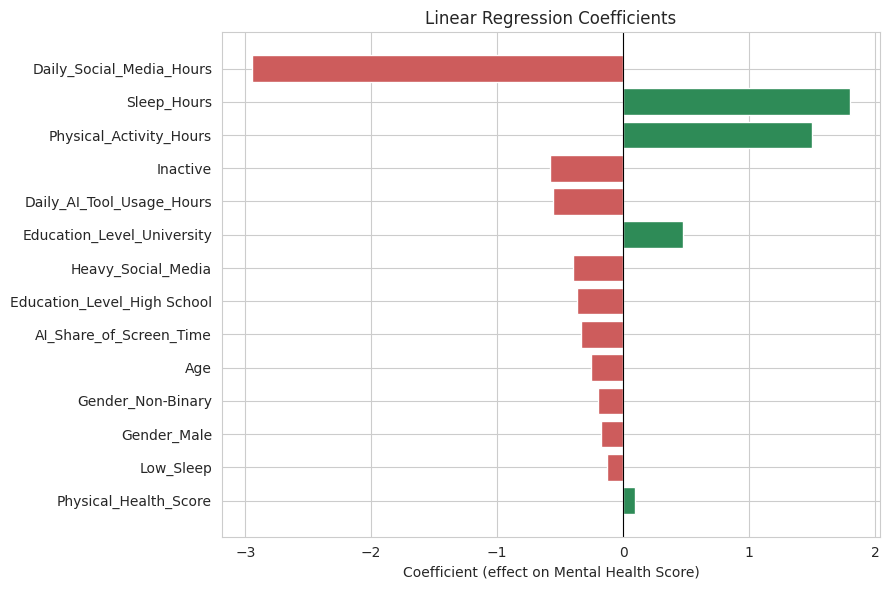

In [103]:
plt.figure(figsize=(9, 6))
colors = ["seagreen" if c > 0 else "indianred" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (effect on Mental Health Score)")
plt.title("Linear Regression Coefficients")
plt.tight_layout()
plt.show()

In [104]:
# Variance Inflation Factor (VIF): values above ~5-10 indicate problematic multicollinearity
vif_rows = []
for i, name in enumerate(feature_names):
    others = np.delete(X_train_t, i, axis=1)
    r2_i = LinearRegression().fit(others, X_train_t[:, i]).score(others, X_train_t[:, i])
    vif_rows.append([name, 1 / (1 - r2_i) if r2_i < 1 else np.inf])

vif_df = pd.DataFrame(vif_rows, columns=["Feature", "VIF"]).sort_values("VIF", ascending=False)
vif_df.round(2).reset_index(drop=True)

,Feature,VIF
0,Age,9.13
1,Daily_Social_Media_Hours,5.81
2,AI_Share_of_Screen_Time,5.47
3,Education_Level_High School,4.47
4,Education_Level_University,3.65
5,Daily_AI_Tool_Usage_Hours,3.50
6,Heavy_Social_Media,2.71
7,Sleep_Hours,2.63
8,Low_Sleep,2.48
9,Physical_Activity_Hours,2.31


## Block 14: Parameter tuning with Ridge and Lasso (regularised linear regression)
Plain Linear Regression has almost no parameters, so we also try its regularised versions
and choose `alpha` with 5-fold cross-validation.

In [105]:
ridge_pipe = Pipeline([("prep", preprocessor), ("model", Ridge())])
lasso_pipe = Pipeline([("prep", preprocessor), ("model", Lasso(max_iter=10000))])

ridge_grid = GridSearchCV(ridge_pipe, {"model__alpha": [0.01, 0.1, 1, 10, 100, 500, 1000]},
                          cv=cv, scoring="r2", n_jobs=-1)
lasso_grid = GridSearchCV(lasso_pipe, {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 0.5, 1]},
                          cv=cv, scoring="r2", n_jobs=-1)

start = time.time(); ridge_grid.fit(X_train, y_train); ridge_time = time.time() - start
start = time.time(); lasso_grid.fit(X_train, y_train); lasso_time = time.time() - start

print("Best Ridge alpha :", ridge_grid.best_params_, "| CV R2:", round(ridge_grid.best_score_, 4))
print("Best Lasso alpha :", lasso_grid.best_params_, "| CV R2:", round(lasso_grid.best_score_, 4))

Best Ridge alpha : {'model__alpha': 100} | CV R2: 0.2458
Best Lasso alpha : {'model__alpha': 0.01} | CV R2: 0.2459


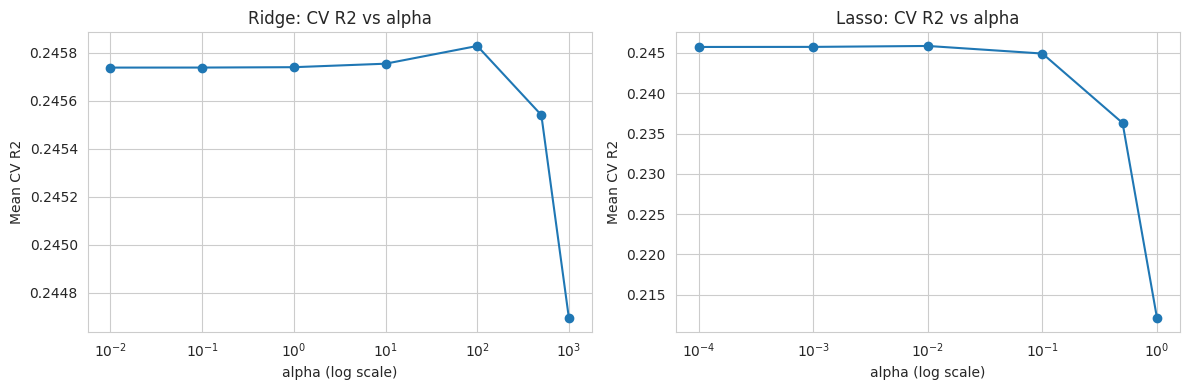

In [106]:
# See how R2 changes with alpha
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, grid, title in [(ax[0], ridge_grid, "Ridge"), (ax[1], lasso_grid, "Lasso")]:
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    a.semilogx(alphas, grid.cv_results_["mean_test_score"], marker="o")
    a.set_xlabel("alpha (log scale)")
    a.set_ylabel("Mean CV R2")
    a.set_title(f"{title}: CV R2 vs alpha")
plt.tight_layout()
plt.show()

## Block 15: Dimensionality reduction with PCA (feature extraction)

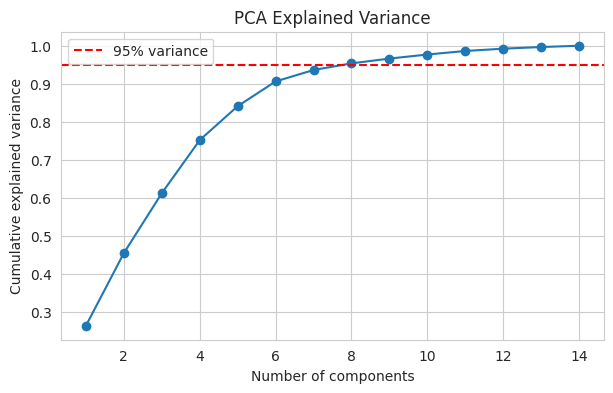

Components needed for 95% variance: 8 out of 14


In [107]:
# How many components are needed to keep 95% of the variance?
pca_check = PCA().fit(X_train_t)
cum_var = np.cumsum(pca_check.explained_variance_ratio_)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="r", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.show()
print("Components needed for 95% variance:", n_95, "out of", X_train_t.shape[1])

In [108]:
pca_pipe = Pipeline([("prep", preprocessor), ("pca", PCA(n_components=0.95)), ("model", LinearRegression())])

start = time.time()
pca_pipe.fit(X_train, y_train)
pca_time = time.time() - start

pca_results = evaluate(pca_pipe, X_train, y_train, X_test, y_test, "PCA + Linear Regression")
pca_results.round(4)

,Model,Set,R2,MAE,MSE,RMSE,MAPE %
0,PCA + Linear Regression,Train,0.2463,6.3793,64.6021,8.0375,9.4006
1,PCA + Linear Regression,Test,0.2385,6.3300,64.2469,8.0154,9.2791


## Block 16: Final model comparison

In [109]:
ridge_best = ridge_grid.best_estimator_
lasso_best = lasso_grid.best_estimator_

all_results = pd.concat([
    lin_results,
    evaluate(ridge_best, X_train, y_train, X_test, y_test, "Ridge"),
    evaluate(lasso_best, X_train, y_train, X_test, y_test, "Lasso"),
    pca_results,
], ignore_index=True)

test_comparison = all_results[all_results["Set"] == "Test"].drop(columns="Set").reset_index(drop=True)
test_comparison["Train time (s)"] = [lin_train_time, ridge_time, lasso_time, pca_time]
test_comparison.round(4)

,Model,R2,MAE,MSE,RMSE,MAPE %,Train time (s)
0,Linear Regression,0.2390,6.3280,64.2045,8.0128,9.2751,0.0410
1,Ridge,0.2392,6.3276,64.1835,8.0115,9.2751,2.7343
2,Lasso,0.2395,6.3268,64.1576,8.0098,9.2729,1.0630
3,PCA + Linear Regression,0.2385,6.3300,64.2469,8.0154,9.2791,0.0339


In [110]:
# Which features did Lasso keep or shrink to zero?
lasso_coefs = pd.Series(lasso_best.named_steps["model"].coef_, index=feature_names)
print("Lasso coefficients:")
print(lasso_coefs.round(3).sort_values(key=abs, ascending=False))
print("\nFeatures removed by Lasso:", list(lasso_coefs[lasso_coefs == 0].index))

Lasso coefficients:
Daily_Social_Media_Hours      -2.945
Sleep_Hours                    1.822
Physical_Activity_Hours        1.510
Daily_AI_Tool_Usage_Hours     -0.567
Inactive                      -0.512
Heavy_Social_Media            -0.338
AI_Share_of_Screen_Time       -0.307
Education_Level_University     0.176
Gender_Male                   -0.124
Physical_Health_Score          0.093
Low_Sleep                     -0.057
Education_Level_High School   -0.041
Age                           -0.000
Gender_Non-Binary             -0.000
dtype: float64

Features removed by Lasso: ['Age', 'Gender_Non-Binary']


## Block 17: Use the model on a new student (prediction example)

In [111]:
new_student = pd.DataFrame([{
    "Age": 20,
    "Gender": "Female",
    "Education_Level": "University",
    "Daily_Social_Media_Hours": 7.0,
    "Daily_AI_Tool_Usage_Hours": 2.0,
    "Sleep_Hours": 5.5,
    "Physical_Activity_Hours": 0.5,
    "Physical_Health_Score": 75.0,
}])

# apply the same feature engineering as before
screen = new_student["Daily_Social_Media_Hours"] + new_student["Daily_AI_Tool_Usage_Hours"]
new_student["AI_Share_of_Screen_Time"] = np.where(screen > 0, new_student["Daily_AI_Tool_Usage_Hours"] / screen, 0)
new_student["Heavy_Social_Media"] = (new_student["Daily_Social_Media_Hours"] >= 6).astype(int)
new_student["Low_Sleep"] = (new_student["Sleep_Hours"] < 6).astype(int)
new_student["Inactive"] = (new_student["Physical_Activity_Hours"] < 0.5).astype(int)

new_student = new_student[X.columns]   # same column order as training
print("Predicted Mental Health Score:", round(lin_pipe.predict(new_student)[0], 2))

Predicted Mental Health Score: 67.45


### Interactive Student Mental Health Prediction

In [112]:
def get_input(prompt, default_val, val_type=float):
    try:
        user_in = input(f"{prompt} [default: {default_val}]: ")
        if not user_in.strip():
            return default_val
        return val_type(user_in)
    except Exception:
        print(f"Invalid input. Using default: {default_val}")
        return default_val

print("--- Enter Student Details for Prediction ---")
age = get_input("Age", 20, int)
gender = input("Gender (Male, Female, Non-binary) [default: Female]: ").strip().title() or "Female"
edu = input("Education Level (High School, College, University) [default: University]: ").strip().title() or "University"
social_hours = get_input("Daily Social Media Hours", 7.0, float)
ai_hours = get_input("Daily AI Tool Usage Hours", 2.0, float)
sleep = get_input("Sleep Hours", 5.5, float)
physical_hours = get_input("Physical Activity Hours", 0.5, float)
physical_score = get_input("Physical Health Score (0-100)", 75.0, float)

# Create DataFrame
custom_student = pd.DataFrame([{
    "Age": age,
    "Gender": gender,
    "Education_Level": edu,
    "Daily_Social_Media_Hours": social_hours,
    "Daily_AI_Tool_Usage_Hours": ai_hours,
    "Sleep_Hours": sleep,
    "Physical_Activity_Hours": physical_hours,
    "Physical_Health_Score": physical_score
}])

# Apply feature engineering
total_screen = custom_student["Daily_Social_Media_Hours"] + custom_student["Daily_AI_Tool_Usage_Hours"]
custom_student["AI_Share_of_Screen_Time"] = np.where(total_screen > 0, custom_student["Daily_AI_Tool_Usage_Hours"] / total_screen, 0)
custom_student["Heavy_Social_Media"] = (custom_student["Daily_Social_Media_Hours"] >= 6).astype(int)
custom_student["Low_Sleep"] = (custom_student["Sleep_Hours"] < 6).astype(int)
custom_student["Inactive"] = (custom_student["Physical_Activity_Hours"] < 0.5).astype(int)

# Match features with X columns
custom_student = custom_student[X.columns]

# Predict
predicted_score = lin_pipe.predict(custom_student)[0]
print(f"Predicted Mental Health Score: {predicted_score:.2f}")

--- Enter Student Details for Prediction ---
Age [default: 20]: 21
Gender (Male, Female, Non-binary) [default: Female]: male
Education Level (High School, College, University) [default: University]: 
Daily Social Media Hours [default: 7.0]: 9
Daily AI Tool Usage Hours [default: 2.0]: 3
Sleep Hours [default: 5.5]: 9
Physical Activity Hours [default: 0.5]: 2
Physical Health Score (0-100) [default: 75.0]: 70
Predicted Mental Health Score: 71.62
